In [1]:

# STEP 1A: Import required libraries

import pandas as pd
import numpy as np

# Make results reproducible
np.random.seed(42)

print("QuickCommerce AI Project")
print("Libraries imported successfully!")


QuickCommerce AI Project
Libraries imported successfully!


In [2]:

# STEP 1B: Generate synthetic cart data

n = 5000

cart_value = np.random.uniform(100, 2000, n).round(2)
delivery_fee = np.random.choice([0, 10, 20, 30, 40, 50], n)
items_in_cart = np.random.randint(1, 16, n)
out_of_stock_items = np.random.choice([0, 1, 2], n, p=[0.85, 0.12, 0.03])
eta_minutes = np.random.randint(5, 46, n)
previous_orders = np.random.randint(0, 31, n)
discount_percent = np.random.choice([0, 5, 10, 15, 20], n)

# Simulate a relationship between cart characteristics
# and the likelihood of abandonment.
# These assumptions are for demonstration, not real company data.

risk_score = (
    -1.2
    + 0.035 * delivery_fee
    + 0.035 * (eta_minutes - 20)
    + 0.75 * out_of_stock_items
    - 0.035 * previous_orders
    - 0.025 * discount_percent
    + 0.15 * (items_in_cart <= 2)
)

# Convert risk score into a probability between 0 and 1
abandonment_probability = 1 / (1 + np.exp(-risk_score))

# Generate the observed outcome for each simulated session
abandoned = np.random.binomial(1, abandonment_probability)

cart_data = pd.DataFrame({
    "cart_value": cart_value,
    "delivery_fee": delivery_fee,
    "items_in_cart": items_in_cart,
    "out_of_stock_items": out_of_stock_items,
    "eta_minutes": eta_minutes,
    "previous_orders": previous_orders,
    "discount_percent": discount_percent,
    "abandoned": abandoned
})

# Save the dataset
cart_data.to_csv("cart_data.csv", index=False)

print("Cart dataset created successfully!")
print("Dataset shape:", cart_data.shape)

display(cart_data.head(10))


Cart dataset created successfully!
Dataset shape: (5000, 8)


,cart_value,delivery_fee,items_in_cart,out_of_stock_items,eta_minutes,previous_orders,discount_percent,abandoned
0,811.63,20,15,0,40,22,10,0
1,1906.36,20,11,1,7,23,15,0
2,1490.79,50,4,0,8,9,20,0
3,1237.45,30,7,0,35,17,15,0
4,396.44,20,9,0,6,22,5,0
5,396.39,40,14,0,18,15,15,1
6,210.36,20,8,0,41,28,20,0
7,1745.73,40,8,1,35,11,15,1
8,1242.12,20,9,0,6,18,0,0
9,1445.34,40,14,2,35,23,20,1


In [3]:

# STEP 1C: Generate synthetic inventory and sales history

inventory_records = []

products = [
    "Milk", "Bread", "Eggs", "Rice", "Wheat Flour",
    "Cooking Oil", "Sugar", "Tea", "Coffee", "Butter",
    "Cheese", "Yogurt", "Bananas", "Apples", "Potatoes",
    "Onions", "Tomatoes", "Biscuits", "Chips", "Chocolate",
    "Soft Drinks", "Bottled Water", "Instant Noodles",
    "Pasta", "Detergent", "Shampoo", "Soap", "Toothpaste",
    "Baby Wipes", "Ice Cream"
]

for product in products:

    # Typical daily demand differs by product
    average_demand = np.random.randint(15, 120)

    # Simulate 90 days of sales history
    for day in range(90):

        # Add day-of-week effects and random demand variation
        weekday = day % 7

        weekend_factor = 1.20 if weekday in [5, 6] else 1.0

        daily_demand = max(
            0,
            int(np.random.normal(
                average_demand * weekend_factor, 8
            ))
        )

        # Illustrative stock and supplier characteristics
        supplier_lead_time = np.random.choice([1, 2, 3])
        safety_stock = int(average_demand * 0.30)
        unit_cost = round(np.random.uniform(10, 200), 2)

        inventory_records.append({
            "day": day + 1,
            "product": product,
            "daily_sales": daily_demand,
            "supplier_lead_time": supplier_lead_time,
            "safety_stock": safety_stock,
            "unit_cost": unit_cost
        })

inventory_data = pd.DataFrame(inventory_records)

# Add current stock as a simulated snapshot
current_stock = {}

for product in products:
    average_sales = inventory_data.loc[
        inventory_data["product"] == product, "daily_sales"
    ].mean()

    current_stock[product] = max(
        0,
        int(np.random.uniform(0.2, 2.0) * average_sales)
    )

inventory_data["current_stock"] = inventory_data["product"].map(
    current_stock
)

inventory_data.to_csv("inventory_data.csv", index=False)

print("Inventory dataset created successfully!")
print("Dataset shape:", inventory_data.shape)

display(inventory_data.head(10))


Inventory dataset created successfully!
Dataset shape: (2700, 7)


,day,product,daily_sales,supplier_lead_time,safety_stock,unit_cost,current_stock
0,1,Milk,76,3,21,122.45,105
1,2,Milk,77,3,21,108.75,105
2,3,Milk,63,3,21,127.46,105
3,4,Milk,64,2,21,105.61,105
4,5,Milk,65,1,21,58.10,105
5,6,Milk,73,2,21,183.03,105
6,7,Milk,82,1,21,194.36,105
7,8,Milk,88,3,21,171.58,105
8,9,Milk,76,2,21,111.62,105
9,10,Milk,91,3,21,119.39,105


In [4]:

# STEP 1D: Validate and summarize both datasets

print("CART DATA")
print("Rows and columns:", cart_data.shape)
print("Missing values:", cart_data.isnull().sum().sum())
print("Abandonment rate:", round(cart_data["abandoned"].mean() * 100, 2), "%")

print("\nINVENTORY DATA")
print("Rows and columns:", inventory_data.shape)
print("Missing values:", inventory_data.isnull().sum().sum())
print("Number of products:", inventory_data["product"].nunique())

print("\nAverage daily sales by product:")
display(
    inventory_data.groupby("product")["daily_sales"]
    .mean()
    .round(2)
    .head(10)
)

print("\nBoth datasets are ready for the next step!")


CART DATA
Rows and columns: (5000, 8)
Missing values: 0
Abandonment rate: 33.38 %

INVENTORY DATA
Rows and columns: (2700, 7)
Missing values: 0
Number of products: 30

Average daily sales by product:


product
Apples            56.29
Baby Wipes        90.00
Bananas           94.12
Biscuits          40.47
Bottled Water     39.93
Bread             30.00
Butter            15.53
Cheese           107.92
Chips             42.12
Chocolate         72.23
Name: daily_sales, dtype: float64


Both datasets are ready for the next step!


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the two datasets
cart_data = pd.read_csv("cart_data.csv")
inventory_data = pd.read_csv("inventory_data.csv")

print("Cart dataset shape:", cart_data.shape)
print("Inventory dataset shape:", inventory_data.shape)

display(cart_data.head())
display(inventory_data.head())


Cart dataset shape: (5000, 8)
Inventory dataset shape: (2700, 7)


,cart_value,delivery_fee,items_in_cart,out_of_stock_items,eta_minutes,previous_orders,discount_percent,abandoned
0,811.63,20,15,0,40,22,10,0
1,1906.36,20,11,1,7,23,15,0
2,1490.79,50,4,0,8,9,20,0
3,1237.45,30,7,0,35,17,15,0
4,396.44,20,9,0,6,22,5,0


,day,product,daily_sales,supplier_lead_time,safety_stock,unit_cost,current_stock
0,1,Milk,76,3,21,122.45,105
1,2,Milk,77,3,21,108.75,105
2,3,Milk,63,3,21,127.46,105
3,4,Milk,64,2,21,105.61,105
4,5,Milk,65,1,21,58.10,105


In [7]:

print("CART DATA QUALITY")
print("\nData types:")
print(cart_data.dtypes)

print("\nMissing values:")
display(cart_data.isnull().sum())

print("\nDuplicate rows:", cart_data.duplicated().sum())

print("\nINVENTORY DATA QUALITY")
print("\nData types:")
print(inventory_data.dtypes)

print("\nMissing values:")
display(inventory_data.isnull().sum())

print("\nDuplicate rows:", inventory_data.duplicated().sum())


CART DATA QUALITY

Data types:
cart_value            float64
delivery_fee            int64
items_in_cart           int64
out_of_stock_items      int64
eta_minutes             int64
previous_orders         int64
discount_percent        int64
abandoned               int64
dtype: object

Missing values:


cart_value            0
delivery_fee          0
items_in_cart         0
out_of_stock_items    0
eta_minutes           0
previous_orders       0
discount_percent      0
abandoned             0
dtype: int64


Duplicate rows: 0

INVENTORY DATA QUALITY

Data types:
day                     int64
product                object
daily_sales             int64
supplier_lead_time      int64
safety_stock            int64
unit_cost             float64
current_stock           int64
dtype: object

Missing values:


day                   0
product               0
daily_sales           0
supplier_lead_time    0
safety_stock          0
unit_cost             0
current_stock         0
dtype: int64


Duplicate rows: 0


In [8]:

# Count abandoned and completed carts

cart_counts = cart_data["abandoned"].value_counts().sort_index()

print("Completed carts (0):", cart_counts.get(0, 0))
print("Abandoned carts (1):", cart_counts.get(1, 0))

abandonment_rate = cart_data["abandoned"].mean() * 100

print(f"Overall abandonment rate: {abandonment_rate:.2f}%")


Completed carts (0): 3331
Abandoned carts (1): 1669
Overall abandonment rate: 33.38%


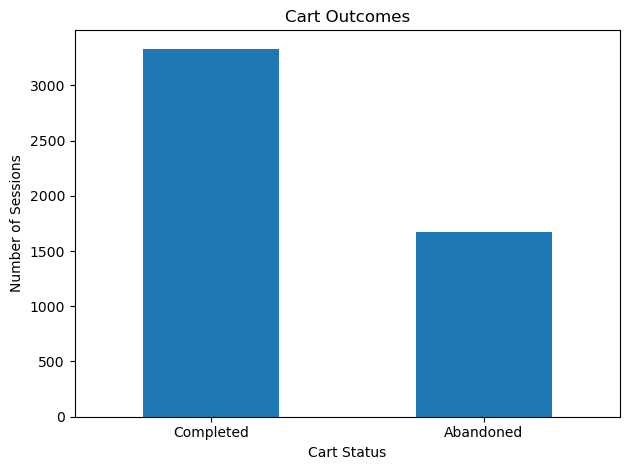

In [9]:

# Visualize cart abandonment

cart_labels = cart_data["abandoned"].map({
    0: "Completed",
    1: "Abandoned"
})

cart_labels.value_counts().reindex(
    ["Completed", "Abandoned"]
).plot(kind="bar")

plt.title("Cart Outcomes")
plt.xlabel("Cart Status")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [10]:

# Compare average abandonment across different factors

print("Abandonment rate by delivery fee:")
display(
    cart_data.groupby("delivery_fee")["abandoned"]
    .mean()
    .mul(100)
    .round(2)
    .rename("Abandonment Rate (%)")
)

print("Abandonment rate by delivery time:")
display(
    cart_data.groupby("eta_minutes")["abandoned"]
    .mean()
    .mul(100)
    .round(2)
    .rename("Abandonment Rate (%)")
    .head(15)
)

print("Abandonment rate by unavailable items:")
display(
    cart_data.groupby("out_of_stock_items")["abandoned"]
    .mean()
    .mul(100)
    .round(2)
    .rename("Abandonment Rate (%)")
)


Abandonment rate by delivery fee:


delivery_fee
0     18.38
10    20.46
20    28.43
30    35.34
40    44.68
50    55.91
Name: Abandonment Rate (%), dtype: float64

Abandonment rate by delivery time:


eta_minutes
5     16.35
6     27.42
7     21.19
8     20.51
9     18.49
10    20.87
11    26.81
12    20.34
13    31.78
14    23.81
15    23.57
16    26.56
17    17.74
18    23.08
19    36.51
Name: Abandonment Rate (%), dtype: float64

Abandonment rate by unavailable items:


out_of_stock_items
0    30.28
1    46.12
2    69.66
Name: Abandonment Rate (%), dtype: float64

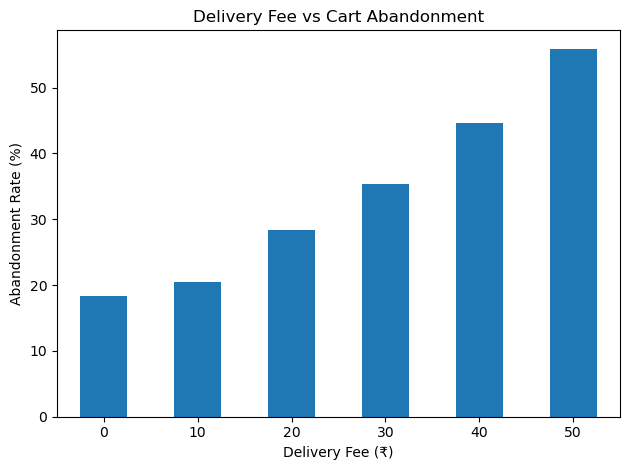

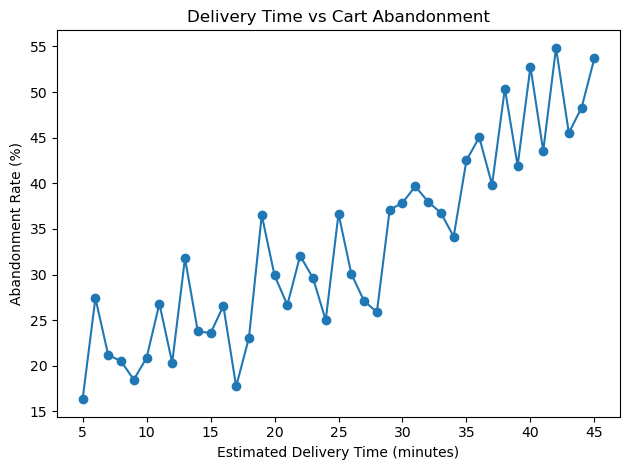

In [11]:

# Chart 1: Delivery fee vs abandonment rate

fee_rates = (
    cart_data.groupby("delivery_fee")["abandoned"].mean() * 100
)

fee_rates.plot(kind="bar")
plt.title("Delivery Fee vs Cart Abandonment")
plt.xlabel("Delivery Fee (₹)")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: Delivery ETA vs abandonment rate

eta_rates = (
    cart_data.groupby("eta_minutes")["abandoned"].mean() * 100
)

eta_rates.plot(kind="line", marker="o")
plt.title("Delivery Time vs Cart Abandonment")
plt.xlabel("Estimated Delivery Time (minutes)")
plt.ylabel("Abandonment Rate (%)")
plt.tight_layout()
plt.show()


In [12]:

# Summarize demand by product

product_summary = (
    inventory_data.groupby("product")
    .agg(
        average_daily_sales=("daily_sales", "mean"),
        maximum_daily_sales=("daily_sales", "max"),
        minimum_daily_sales=("daily_sales", "min"),
        current_stock=("current_stock", "first"),
        supplier_lead_time=("supplier_lead_time", "first"),
        safety_stock=("safety_stock", "first"),
        unit_cost=("unit_cost", "first")
    )
    .round(2)
)

display(product_summary.head(10))


,average_daily_sales,maximum_daily_sales,minimum_daily_sales,current_stock,supplier_lead_time,safety_stock,unit_cost
product,,,,,,,
Apples,56.29,78,35,73,1,16,138.81
Baby Wipes,90.00,124,67,93,1,25,130.33
Bananas,94.12,124,64,119,1,27,120.03
Biscuits,40.47,59,18,43,2,11,39.04
Bottled Water,39.93,60,14,34,2,11,123.14
Bread,30.00,57,12,45,3,8,109.12
Butter,15.53,39,0,9,1,4,85.46
Cheese,107.92,146,78,160,2,30,128.54
Chips,42.12,69,23,9,1,12,49.67


In [13]:

# Basic inventory replenishment analysis

product_summary["reorder_point"] = (
    product_summary["average_daily_sales"]
    * product_summary["supplier_lead_time"]
    + product_summary["safety_stock"]
)

product_summary["stock_status"] = np.where(
    product_summary["current_stock"]
    <= product_summary["reorder_point"],
    "Reorder Required",
    "Stock Sufficient"
)

product_summary["suggested_reorder_quantity"] = np.maximum(
    0,
    np.ceil(
        product_summary["reorder_point"]
        - product_summary["current_stock"]
    )
).astype(int)

display(
    product_summary.sort_values(
        "current_stock"
    )[[
        "average_daily_sales",
        "current_stock",
        "reorder_point",
        "stock_status",
        "suggested_reorder_quantity"
    ]].head(15)
)


,average_daily_sales,current_stock,reorder_point,stock_status,suggested_reorder_quantity
product,,,,,
Butter,15.53,9,19.53,Reorder Required,11
Chips,42.12,9,54.12,Reorder Required,46
Pasta,79.54,19,101.54,Reorder Required,83
Soft Drinks,52.47,22,119.94,Reorder Required,98
Bottled Water,39.93,34,90.86,Reorder Required,57
Tomatoes,21.86,41,27.86,Stock Sufficient,0
Biscuits,40.47,43,91.94,Reorder Required,49
Tea,32.30,43,41.30,Stock Sufficient,0
Bread,30.00,45,98.00,Reorder Required,53


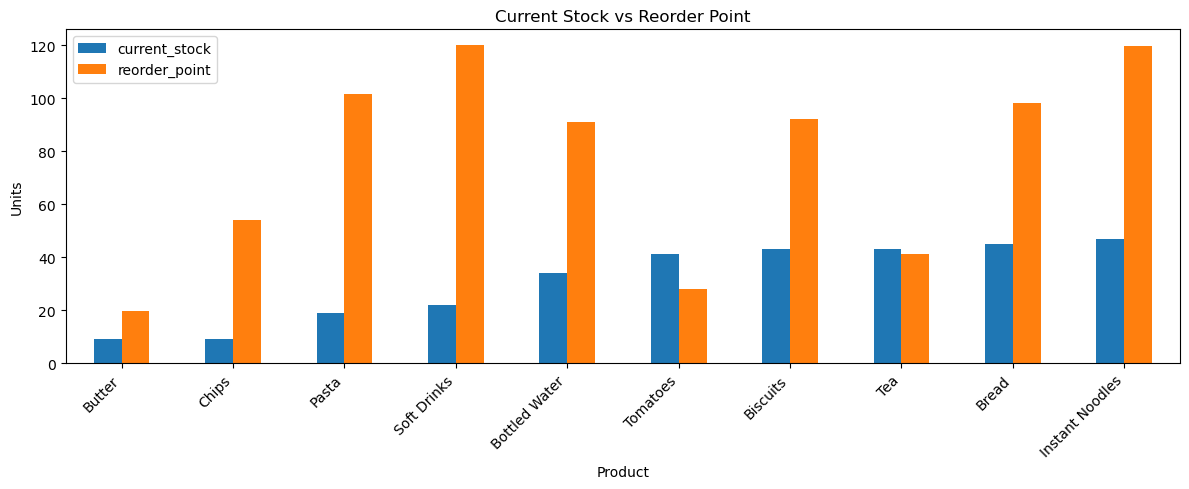

In [14]:

# Select the 10 products with the lowest current stock

lowest_stock = product_summary.sort_values(
    "current_stock"
).head(10)

lowest_stock[["current_stock", "reorder_point"]].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Current Stock vs Reorder Point")
plt.xlabel("Product")
plt.ylabel("Units")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [16]:
!pip install scikit-learn

In [17]:

# Step 3.1: Import machine-learning libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Machine-learning libraries imported successfully!")


Machine-learning libraries imported successfully!


In [18]:

# Step 3.2: Load and prepare the data

cart_data = pd.read_csv("cart_data.csv")

features = [
    "cart_value",
    "delivery_fee",
    "items_in_cart",
    "out_of_stock_items",
    "eta_minutes",
    "previous_orders",
    "discount_percent"
]

X = cart_data[features]
y = cart_data["abandoned"]

print("Number of sessions:", len(cart_data))
print("Number of input features:", len(features))

print("\nTarget distribution:")
print(y.value_counts().rename({
    0: "Completed",
    1: "Abandoned"
}))


Number of sessions: 5000
Number of input features: 7

Target distribution:
abandoned
Completed    3331
Abandoned    1669
Name: count, dtype: int64


In [19]:

# Step 3.3: Split data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training sessions:", len(X_train))
print("Testing sessions:", len(X_test))


Training sessions: 4000
Testing sessions: 1000


In [20]:

# Step 3.4: Build and train the model

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [21]:

# Step 3.5: Evaluate model performance

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("MODEL PERFORMANCE")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.3f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Completed", "Abandoned"],
    zero_division=0
))


MODEL PERFORMANCE
-----------------------------------
Accuracy:  0.721
Precision: 0.641
Recall:    0.374
F1-score:  0.473
ROC-AUC:   0.750

Detailed classification report:
              precision    recall  f1-score   support

   Completed       0.74      0.89      0.81       666
   Abandoned       0.64      0.37      0.47       334

    accuracy                           0.72      1000
   macro avg       0.69      0.63      0.64      1000
weighted avg       0.71      0.72      0.70      1000



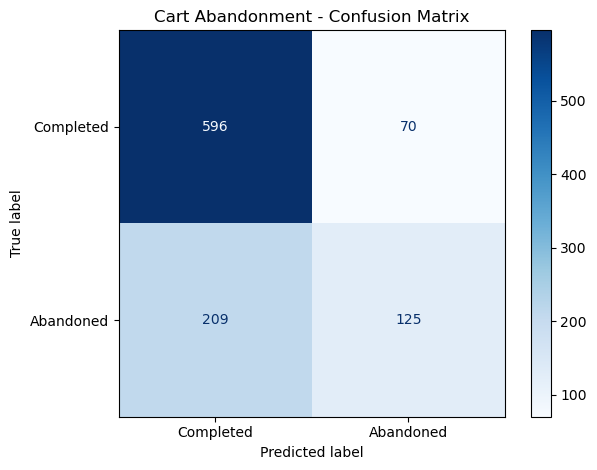

In [22]:

# Step 3.6: Visualize prediction errors

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Completed", "Abandoned"],
    cmap="Blues"
)

plt.title("Cart Abandonment - Confusion Matrix")
plt.tight_layout()
plt.show()


In [23]:

# Step 3.7: Predict abandonment risk for a new cart

new_cart = pd.DataFrame([{
    "cart_value": 450,
    "delivery_fee": 40,
    "items_in_cart": 3,
    "out_of_stock_items": 1,
    "eta_minutes": 35,
    "previous_orders": 1,
    "discount_percent": 0
}])

probability = logistic_model.predict_proba(new_cart)[0, 1]

print(f"Estimated abandonment probability: {probability:.1%}")

if probability >= 0.70:
    print("Recommendation: High risk. Investigate suitable retention actions.")
elif probability >= 0.40:
    print("Recommendation: Medium risk. Consider a helpful reminder.")
else:
    print("Recommendation: Low risk. Continue the normal customer journey.")


Estimated abandonment probability: 83.3%
Recommendation: High risk. Investigate suitable retention actions.


In [24]:

# Step 3.8: Save the trained model

import joblib

joblib.dump(logistic_model, "cart_abandonment_model.pkl")

print("Model saved as cart_abandonment_model.pkl")


Model saved as cart_abandonment_model.pkl


In [25]:

# STEP 4.1: Import and train Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)

# Train using exactly the same training data
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [26]:

# STEP 4.2: Generate predictions

# Logistic Regression predictions
lr_predictions = logistic_model.predict(X_test)
lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest predictions
rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]


def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


comparison = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test, lr_predictions, lr_probabilities
    ),
    evaluate_model(
        "Random Forest",
        y_test, rf_predictions, rf_probabilities
    )
])

display(comparison.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.721,0.641,0.374,0.473,0.750
1,Random Forest,0.687,0.530,0.548,0.539,0.741


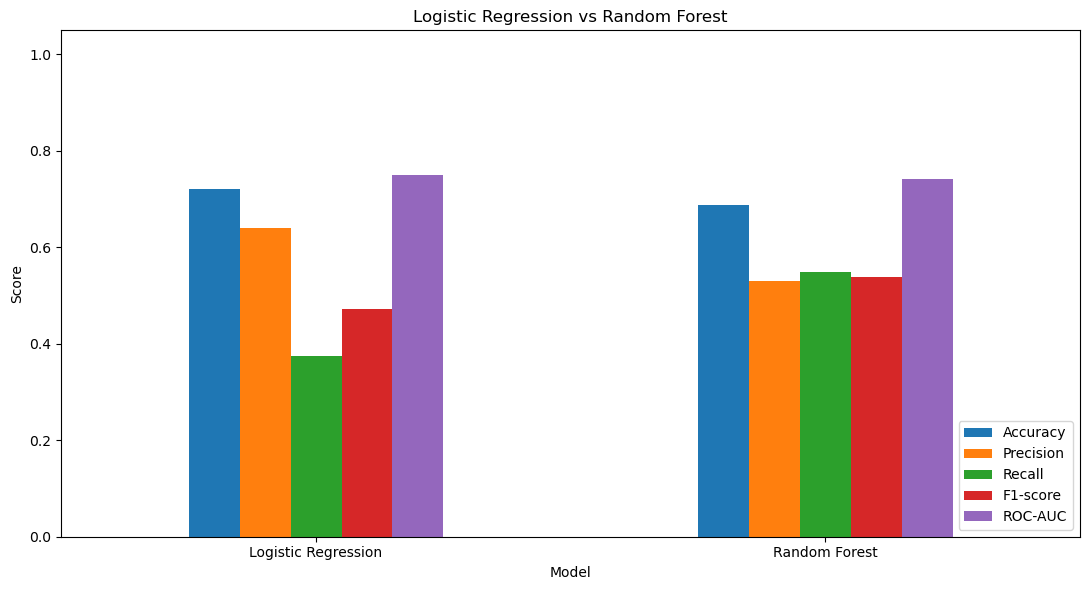

In [27]:

# STEP 4.3: Compare performance visually

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


,Feature,Importance
4,eta_minutes,0.232757
1,delivery_fee,0.223204
0,cart_value,0.163122
5,previous_orders,0.159664
2,items_in_cart,0.096220
3,out_of_stock_items,0.068497
6,discount_percent,0.056536


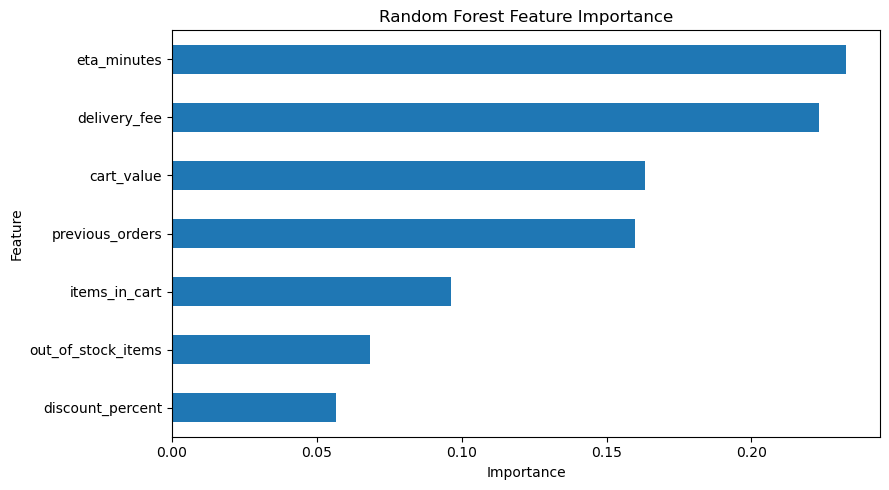

In [28]:

# STEP 4.4: Examine Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

feature_importance.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [29]:

# STEP 4.5: Select a preliminary model

best_model_name = comparison.sort_values(
    "ROC-AUC", ascending=False
).iloc[0]["Model"]

if best_model_name == "Logistic Regression":
    best_cart_model = logistic_model
else:
    best_cart_model = random_forest_model

print("Preliminary model selected:", best_model_name)


Preliminary model selected: Logistic Regression


In [30]:

# STEP 4.6: Save the selected model

import joblib

joblib.dump(best_cart_model, "cart_abandonment_model.pkl")

print("Selected cart model saved successfully!")


Selected cart model saved successfully!


In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

inventory_data = pd.read_csv("inventory_data.csv")

print("Inventory data loaded!")
print("Rows:", len(inventory_data))
print("Products:", inventory_data["product"].nunique())

display(inventory_data.head())


Inventory data loaded!
Rows: 2700
Products: 30


,day,product,daily_sales,supplier_lead_time,safety_stock,unit_cost,current_stock
0,1,Milk,76,3,21,122.45,105
1,2,Milk,77,3,21,108.75,105
2,3,Milk,63,3,21,127.46,105
3,4,Milk,64,2,21,105.61,105
4,5,Milk,65,1,21,58.10,105


In [32]:

# STEP 5.2: Create time-based features

forecast_data = inventory_data.sort_values(
    ["product", "day"]
).copy()

# Previous days' sales, shifted so today's target is not used
forecast_data["sales_lag_1"] = (
    forecast_data.groupby("product")["daily_sales"].shift(1)
)

forecast_data["sales_lag_2"] = (
    forecast_data.groupby("product")["daily_sales"].shift(2)
)

forecast_data["sales_lag_3"] = (
    forecast_data.groupby("product")["daily_sales"].shift(3)
)

# Average sales over the previous seven days
forecast_data["sales_7day_avg"] = (
    forecast_data.groupby("product")["daily_sales"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

# Day of the week: day 1 is Monday in our simulated dataset
forecast_data["weekday"] = (
    (forecast_data["day"] - 1) % 7
)

# Target: the sales observed on the day we are predicting
forecast_data["target_demand"] = forecast_data["daily_sales"]

forecast_data = forecast_data.dropna().reset_index(drop=True)

print("Forecasting dataset prepared!")
print("Rows available:", len(forecast_data))

display(forecast_data.head())


Forecasting dataset prepared!
Rows available: 2490


,day,product,daily_sales,supplier_lead_time,safety_stock,unit_cost,current_stock,sales_lag_1,sales_lag_2,sales_lag_3,sales_7day_avg,weekday,target_demand
0,8,Apples,50,1,16,130.68,73,68.0,70.0,46.0,60.571429,0,50
1,9,Apples,55,3,16,174.39,73,50.0,68.0,70.0,60.714286,1,55
2,10,Apples,68,3,16,194.89,73,55.0,50.0,68.0,58.285714,2,68
3,11,Apples,46,1,16,135.05,73,68.0,55.0,50.0,60.285714,3,46
4,12,Apples,39,3,16,13.56,73,46.0,68.0,55.0,57.571429,4,39


In [33]:

# STEP 5.3: Chronological training and test split

forecast_features = [
    "sales_lag_1",
    "sales_lag_2",
    "sales_lag_3",
    "sales_7day_avg",
    "weekday"
]

# Train on days 8-70, test on days 71-90
train_forecast = forecast_data[
    forecast_data["day"] <= 70
].copy()

test_forecast = forecast_data[
    forecast_data["day"] > 70
].copy()

X_train_inv = train_forecast[forecast_features]
y_train_inv = train_forecast["target_demand"]

X_test_inv = test_forecast[forecast_features]
y_test_inv = test_forecast["target_demand"]

print("Training rows:", len(X_train_inv))
print("Testing rows:", len(X_test_inv))
print("Training period: Days 8-70")
print("Testing period: Days 71-90")


Training rows: 1890
Testing rows: 600
Training period: Days 8-70
Testing period: Days 71-90


In [34]:

# STEP 5.4: Train the demand forecasting model

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

inventory_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42
)

inventory_model.fit(X_train_inv, y_train_inv)

# AI predictions
inventory_predictions = inventory_model.predict(X_test_inv)

# Baseline predictions
baseline_predictions = X_test_inv["sales_7day_avg"].to_numpy()

# Forecast evaluation
ai_mae = mean_absolute_error(y_test_inv, inventory_predictions)
baseline_mae = mean_absolute_error(y_test_inv, baseline_predictions)

ai_rmse = np.sqrt(
    mean_squared_error(y_test_inv, inventory_predictions)
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_inv, baseline_predictions)
)

forecast_comparison = pd.DataFrame({
    "Model": ["7-day Moving Average", "Random Forest"],
    "MAE": [baseline_mae, ai_mae],
    "RMSE": [baseline_rmse, ai_rmse]
})

display(forecast_comparison.round(2))

print("Lower MAE and RMSE indicate smaller forecast errors.")


,Model,MAE,RMSE
0,7-day Moving Average,8.84,11.08
1,Random Forest,6.97,8.86


Lower MAE and RMSE indicate smaller forecast errors.


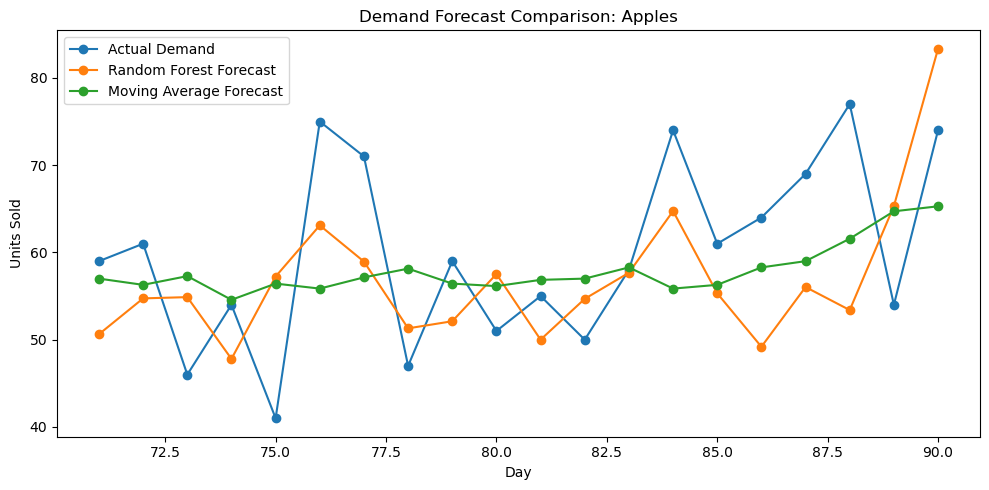

In [35]:

# STEP 5.5: Plot actual versus predicted demand

comparison_plot = test_forecast[["product", "day"]].copy()
comparison_plot["Actual Demand"] = y_test_inv.to_numpy()
comparison_plot["Random Forest"] = inventory_predictions
comparison_plot["Moving Average"] = baseline_predictions

# Display one product to keep the chart readable
selected_product = comparison_plot["product"].iloc[0]

plot_data = comparison_plot[
    comparison_plot["product"] == selected_product
].sort_values("day")

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["day"],
    plot_data["Actual Demand"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    plot_data["day"],
    plot_data["Random Forest"],
    marker="o",
    label="Random Forest Forecast"
)

plt.plot(
    plot_data["day"],
    plot_data["Moving Average"],
    marker="o",
    label="Moving Average Forecast"
)

plt.title(f"Demand Forecast Comparison: {selected_product}")
plt.xlabel("Day")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()


In [36]:

# STEP 5.6: Build a current inventory snapshot

# Use the latest available inventory snapshot per product.
# In our synthetic dataset, these values are repeated per product.
latest_inventory = (
    inventory_data.sort_values("day")
    .groupby("product")
    .tail(1)
    .copy()
)

# Features for predicting demand on the next day
latest_features = (
    inventory_data.sort_values(["product", "day"])
    .groupby("product")
    .tail(7)
    .groupby("product")
    .agg(
        sales_lag_1=("daily_sales", lambda s: s.iloc[-1]),
        sales_lag_2=("daily_sales", lambda s: s.iloc[-2]),
        sales_lag_3=("daily_sales", lambda s: s.iloc[-3]),
        sales_7day_avg=("daily_sales", "mean"),
        last_day=("day", "max")
    )
    .reset_index()
)

# Forecast demand for the day after the final recorded day
latest_features["weekday"] = (
    latest_features["last_day"] % 7
)

latest_features["forecast_demand"] = inventory_model.predict(
    latest_features[forecast_features]
)

# Join forecast results with the inventory snapshot
replenishment = latest_inventory.merge(
    latest_features[["product", "forecast_demand"]],
    on="product",
    how="left"
)

replenishment["reorder_point"] = (
    replenishment["forecast_demand"]
    * replenishment["supplier_lead_time"]
    + replenishment["safety_stock"]
)

# No incoming stock data exists in our sample, so use zero.
replenishment["incoming_stock"] = 0

replenishment["inventory_position"] = (
    replenishment["current_stock"]
    + replenishment["incoming_stock"]
)

replenishment["stock_status"] = np.where(
    replenishment["inventory_position"]
    <= replenishment["reorder_point"],
    "Reorder Required",
    "Stock Sufficient"
)

replenishment["suggested_order_quantity"] = np.ceil(
    np.maximum(
        0,
        replenishment["reorder_point"]
        - replenishment["inventory_position"]
    )
).astype(int)

replenishment["forecast_demand"] = (
    replenishment["forecast_demand"].clip(lower=0)
)

display(
    replenishment[[
        "product",
        "current_stock",
        "forecast_demand",
        "supplier_lead_time",
        "safety_stock",
        "reorder_point",
        "stock_status",
        "suggested_order_quantity"
    ]].sort_values(
        "suggested_order_quantity",
        ascending=False
    ).head(15).round(2)
)


,product,current_stock,forecast_demand,supplier_lead_time,safety_stock,reorder_point,stock_status,suggested_order_quantity
7,Cooking Oil,79,135.63,3,34,440.90,Reorder Required,362
26,Shampoo,157,140.37,3,34,455.12,Reorder Required,299
5,Rice,76,141.26,2,35,317.52,Reorder Required,242
12,Cheese,160,117.66,3,30,382.98,Reorder Required,223
10,Coffee,71,114.90,2,28,257.81,Reorder Required,187
24,Pasta,19,87.73,2,22,197.47,Reorder Required,179
16,Onions,83,112.25,2,28,252.49,Reorder Required,170
1,Toothpaste,52,66.98,3,18,218.95,Reorder Required,167
4,Eggs,109,121.43,2,30,272.86,Reorder Required,164
21,Soft Drinks,22,57.00,3,15,185.99,Reorder Required,164


In [37]:

# STEP 5.7: Save the trained model and feature list

import joblib

joblib.dump(inventory_model, "inventory_demand_model.pkl")

joblib.dump(
    forecast_features,
    "inventory_features.pkl"
)

print("Inventory model saved successfully!")


Inventory model saved successfully!


In [38]:

%pip install streamlit pandas numpy scikit-learn joblib matplotlib


Note: you may need to restart the kernel to use updated packages.


In [40]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor

# --------------------------------------------------
# 1. Application setup & Path Resolver
# --------------------------------------------------

st.set_page_config(
    page_title="QuickCommerce AI Manager",
    page_icon="📦",
    layout="wide"
)

# Fix for NameError: '__file__' in interactive notebooks vs CLI
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()

st.title("📦 QuickCommerce AI Manager")
st.caption(
    "AI-powered cart abandonment prediction "
    "and dark-store inventory replenishment"
)

st.info(
    "Academic prototype using synthetic data. "
    "Predictions do not represent actual Blinkit or Zepto operations."
)

# --------------------------------------------------
# 2. Automated Model & Data Generator (Self-Healing)
# --------------------------------------------------

def ensure_project_files_exist():
    """Generates synthetic datasets and models if they are missing."""
    cart_csv = BASE_DIR / "cart_data.csv"
    inv_csv = BASE_DIR / "inventory_data.csv"
    cart_model_pkl = BASE_DIR / "cart_abandonment_model.pkl"
    inv_model_pkl = BASE_DIR / "inventory_demand_model.pkl"
    inv_feats_pkl = BASE_DIR / "inventory_features.pkl"

    # 1. Create cart_data.csv & cart model if missing
    if not (cart_csv.exists() and cart_model_pkl.exists()):
        np.random.seed(42)
        n_carts = 2000
        c_val = np.round(np.random.normal(520, 150, n_carts).clip(120, 1500), 2)
        d_fee = np.random.choice([0, 15, 25, 40], size=n_carts, p=[0.3, 0.4, 0.2, 0.1])
        items = np.random.randint(1, 15, n_carts)
        oos = np.random.binomial(n=3, p=0.15, size=n_carts)
        eta = np.random.randint(8, 35, n_carts)
        prev_ord = np.random.poisson(lam=5, size=n_carts)
        disc = np.random.choice([0, 5, 10, 15, 20], size=n_carts)

        # Churn/Abandonment logic
        logits = (
            0.08 * (eta - 10)
            + 0.95 * oos
            + 0.04 * d_fee
            - 0.001 * c_val
            - 0.15 * prev_ord
            - 0.03 * disc
            - 0.5
        )
        prob = 1 / (1 + np.exp(-logits))
        abandoned = (prob > 0.45).astype(int)

        cart_df = pd.DataFrame({
            "cart_value": c_val,
            "delivery_fee": d_fee,
            "items_in_cart": items,
            "out_of_stock_items": oos,
            "eta_minutes": eta,
            "previous_orders": prev_ord,
            "discount_percent": disc,
            "abandoned": abandoned
        })
        cart_df.to_csv(cart_csv, index=False)

        cart_X = cart_df.drop(columns=["abandoned"])
        cart_y = cart_df["abandoned"]
        c_model = LogisticRegression(max_iter=1000)
        c_model.fit(cart_X, cart_y)
        joblib.dump(c_model, cart_model_pkl)

    # 2. Create inventory_data.csv & inventory model if missing
    if not (inv_csv.exists() and inv_model_pkl.exists() and inv_feats_pkl.exists()):
        products = ["Amul Gold Milk 500ml", "Brown Bread 400g", "Farm Eggs (Tray 6)", 
                    "Fresh Coriander 100g", "Paneer 200g", "Curd 400g"]
        inv_records = []
        np.random.seed(42)

        for prod in products:
            base_demand = np.random.randint(40, 90)
            lead_time = np.random.choice([1, 2])
            safety = int(base_demand * 0.4)
            current = int(base_demand * np.random.uniform(0.7, 1.8))

            for day in range(1, 31):
                sales = max(5, int(np.random.normal(base_demand, 12)))
                inv_records.append({
                    "day": day,
                    "product": prod,
                    "daily_sales": sales,
                    "current_stock": current if day == 30 else current + np.random.randint(-10, 15),
                    "supplier_lead_time": lead_time,
                    "safety_stock": safety
                })

        inv_df = pd.DataFrame(inv_records)
        inv_df.to_csv(inv_csv, index=False)

        # Train inventory lag regression model
        training_rows = []
        for prod in products:
            p_hist = inv_df[inv_df["product"] == prod].sort_values("day")
            sales_arr = p_hist["daily_sales"].values
            days_arr = p_hist["day"].values
            for i in range(3, len(sales_arr)):
                training_rows.append({
                    "sales_lag_1": sales_arr[i - 1],
                    "sales_lag_2": sales_arr[i - 2],
                    "sales_lag_3": sales_arr[i - 3],
                    "sales_7day_avg": np.mean(sales_arr[max(0, i - 7):i]),
                    "weekday": int(days_arr[i]) % 7,
                    "target_sales": sales_arr[i]
                })

        train_data = pd.DataFrame(training_rows)
        inv_feats = ["sales_lag_1", "sales_lag_2", "sales_lag_3", "sales_7day_avg", "weekday"]
        inv_model = RandomForestRegressor(n_estimators=50, max_depth=5, random_state=42)
        inv_model.fit(train_data[inv_feats], train_data["target_sales"])

        joblib.dump(inv_model, inv_model_pkl)
        joblib.dump(inv_feats, inv_feats_pkl)

ensure_project_files_exist()

# --------------------------------------------------
# 3. Load saved models and data
# --------------------------------------------------

@st.cache_resource
def load_models():
    cart_model = joblib.load(BASE_DIR / "cart_abandonment_model.pkl")
    inventory_model = joblib.load(BASE_DIR / "inventory_demand_model.pkl")
    inventory_features = joblib.load(BASE_DIR / "inventory_features.pkl")
    return cart_model, inventory_model, inventory_features


@st.cache_data
def load_data():
    cart = pd.read_csv(BASE_DIR / "cart_data.csv")
    inventory = pd.read_csv(BASE_DIR / "inventory_data.csv")
    return cart, inventory


try:
    cart_model, inventory_model, inventory_features = load_models()
    cart_data, inventory_data = load_data()
except Exception as error:
    st.error(
        "Could not load project files. Check that app.py, "
        "both model files, inventory_features.pkl and both "
        "CSV files are in the same folder."
    )
    st.exception(error)
    st.stop()

# --------------------------------------------------
# 4. Main navigation
# --------------------------------------------------

dashboard, cart_tab, stock_tab, about_tab = st.tabs([
    "📊 Overview",
    "🛒 Cart Predictor",
    "📦 Inventory Replenishment",
    "ℹ️ About Project"
])

# --------------------------------------------------
# 5. Overview dashboard
# --------------------------------------------------

with dashboard:
    st.subheader("Business Overview")

    total_sessions = len(cart_data)
    abandonment_rate = cart_data["abandoned"].mean() * 100
    product_count = inventory_data["product"].nunique()

    latest_stock = (
        inventory_data.sort_values("day")
        .groupby("product")
        .tail(1)
        .copy()
    )

    stock_alert_count = 0

    for _, row in latest_stock.iterrows():
        product_history = (
            inventory_data[
                inventory_data["product"] == row["product"]
            ].sort_values("day")
        )

        recent_sales = product_history["daily_sales"].tail(7)
        forecast_input = pd.DataFrame([{
            "sales_lag_1": recent_sales.iloc[-1],
            "sales_lag_2": recent_sales.iloc[-2],
            "sales_lag_3": recent_sales.iloc[-3],
            "sales_7day_avg": recent_sales.mean(),
            "weekday": int(row["day"]) % 7
        }])[inventory_features]

        predicted_demand = max(
            0,
            float(inventory_model.predict(forecast_input)[0])
        )

        reorder_point = (
            predicted_demand * row["supplier_lead_time"]
            + row["safety_stock"]
        )

        if row["current_stock"] <= reorder_point:
            stock_alert_count += 1

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Simulated Cart Sessions", f"{total_sessions:,}")
    col2.metric("Cart Abandonment Rate", f"{abandonment_rate:.1f}%")
    col3.metric("Products Tracked", product_count)
    col4.metric("Products Below Reorder Point", stock_alert_count)

    st.subheader("Cart Outcomes")

    outcome_data = (
        cart_data["abandoned"]
        .map({0: "Completed", 1: "Abandoned"})
        .value_counts()
    )

    st.bar_chart(outcome_data)

    st.caption(
        "These are descriptive statistics from the synthetic dataset, "
        "not measured results from a live business."
    )

# --------------------------------------------------
# 6. Cart abandonment prediction
# --------------------------------------------------

with cart_tab:
    st.subheader("Cart Abandonment Predictor")

    st.write(
        "Enter the shopping session details to estimate "
        "the probability of cart abandonment."
    )

    with st.form("cart_form"):
        c1, c2 = st.columns(2)

        with c1:
            cart_value = st.number_input(
                "Cart value (₹)",
                min_value=0.0,
                value=450.0,
                step=50.0
            )

            delivery_fee = st.number_input(
                "Delivery fee (₹)",
                min_value=0.0,
                value=40.0,
                step=5.0
            )

            items_in_cart = st.number_input(
                "Items in cart",
                min_value=1,
                max_value=100,
                value=3
            )

            out_of_stock_items = st.number_input(
                "Unavailable items",
                min_value=0,
                max_value=100,
                value=1
            )

        with c2:
            eta_minutes = st.number_input(
                "Estimated delivery time (minutes)",
                min_value=1,
                max_value=180,
                value=22
            )

            previous_orders = st.number_input(
                "Previous orders",
                min_value=0,
                value=1
            )

            discount_percent = st.number_input(
                "Discount (%)",
                min_value=0,
                max_value=100,
                value=0
            )

        submitted = st.form_submit_button("Predict Abandonment Risk")

    if submitted:
        cart_input = pd.DataFrame([{
            "cart_value": cart_value,
            "delivery_fee": delivery_fee,
            "items_in_cart": items_in_cart,
            "out_of_stock_items": out_of_stock_items,
            "eta_minutes": eta_minutes,
            "previous_orders": previous_orders,
            "discount_percent": discount_percent
        }])

        probability = cart_model.predict_proba(cart_input)[0, 1]

        st.subheader("Prediction Result")
        st.metric(
            "Estimated Abandonment Probability",
            f"{probability:.1%}"
        )

        st.progress(float(probability))

        if probability >= 0.70:
            st.warning(
                "High estimated risk. Review availability, "
                "delivery information and total order cost. "
                "Consider testing a suitable retention action."
            )
        elif probability >= 0.40:
            st.info(
                "Medium estimated risk. Consider clearer "
                "delivery information or an optional reminder."
            )
        else:
            st.success(
                "Low estimated risk. Continue the normal "
                "customer journey."
            )

# --------------------------------------------------
# 7. Inventory replenishment
# --------------------------------------------------

with stock_tab:
    st.subheader("Dark-Store Replenishment")

    st.write(
        "Select a product to estimate demand and calculate "
        "a basic replenishment recommendation."
    )

    products = sorted(inventory_data["product"].unique())

    selected_product = st.selectbox(
        "Select product",
        products
    )

    history = (
        inventory_data[
            inventory_data["product"] == selected_product
        ].sort_values("day")
    )

    latest = history.iloc[-1]
    recent_sales = history["daily_sales"].tail(7)

    current_stock = st.number_input(
        "Current stock (units)",
        min_value=0,
        value=int(latest["current_stock"]),
        step=1
    )

    incoming_stock = st.number_input(
        "Incoming stock (units)",
        min_value=0,
        value=0,
        step=1
    )

    lead_time = st.number_input(
        "Supplier lead time (days)",
        min_value=1,
        max_value=30,
        value=int(latest["supplier_lead_time"])
    )

    safety_stock = st.number_input(
        "Safety stock (units)",
        min_value=0,
        value=int(latest["safety_stock"])
    )

    inventory_input = pd.DataFrame([{
        "sales_lag_1": recent_sales.iloc[-1],
        "sales_lag_2": recent_sales.iloc[-2],
        "sales_lag_3": recent_sales.iloc[-3],
        "sales_7day_avg": recent_sales.mean(),
        "weekday": int(latest["day"]) % 7
    }])[inventory_features]

    predicted_demand = max(
        0,
        float(inventory_model.predict(inventory_input)[0])
    )

    reorder_point = (
        predicted_demand * lead_time + safety_stock
    )

    inventory_position = current_stock + incoming_stock
    order_quantity = int(
        np.ceil(max(0, reorder_point - inventory_position))
    )

    st.divider()

    m1, m2, m3 = st.columns(3)
    m1.metric("Forecast Daily Demand", f"{predicted_demand:.1f} units")
    m2.metric("Reorder Point", f"{reorder_point:.1f} units")
    m3.metric("Suggested Order", f"{order_quantity} units")

    if inventory_position <= reorder_point:
        st.warning(
            f"Replenishment alert: {selected_product} is at or "
            "below the calculated reorder point."
        )
    else:
        st.success(
            f"{selected_product} is currently above the "
            "calculated reorder point."
        )

    st.subheader("Inventory History")
    st.line_chart(
        history.set_index("day")["daily_sales"]
    )

    st.subheader("All Product Inventory")

    all_products = []

    for product in products:
        product_history = (
            inventory_data[
                inventory_data["product"] == product
            ].sort_values("day")
        )

        latest_row = product_history.iloc[-1]
        recent = product_history["daily_sales"].tail(7)

        forecast_input = pd.DataFrame([{
            "sales_lag_1": recent.iloc[-1],
            "sales_lag_2": recent.iloc[-2],
            "sales_lag_3": recent.iloc[-3],
            "sales_7day_avg": recent.mean(),
            "weekday": int(latest_row["day"]) % 7
        }])[inventory_features]

        demand = max(
            0,
            float(inventory_model.predict(forecast_input)[0])
        )

        point = (
            demand * latest_row["supplier_lead_time"]
            + latest_row["safety_stock"]
        )

        all_products.append({
            "Product": product,
            "Current Stock": int(latest_row["current_stock"]),
            "Forecast Demand": round(demand, 1),
            "Reorder Point": round(point, 1),
            "Status": (
                "Reorder Required"
                if latest_row["current_stock"] <= point
                else "Stock Sufficient"
            )
        })

    st.dataframe(
        pd.DataFrame(all_products),
        use_container_width=True,
        hide_index=True
    )

# --------------------------------------------------
# 8. About the project
# --------------------------------------------------

with about_tab:
    st.subheader("About QuickCommerce AI Manager")

    st.markdown("""
    **Business problem**

    Quick-commerce businesses need to improve customer conversion
    while maintaining product availability at dark stores.

    **AI module 1: Cart abandonment**

    - Logistic Regression and Random Forest classification
    - Estimated probability of cart abandonment
    - Illustrative retention recommendations

    **AI module 2: Inventory replenishment**

    - Random Forest demand forecasting
    - Seven-day moving-average baseline
    - Reorder-point calculation and stock alerts

    **Data and limitations**

    This academic prototype uses synthetic data. It is not
    connected to Blinkit or Zepto systems, and its outputs are
    not validated against real customer or inventory outcomes.

    **Responsible use**

    Predictions should support, not replace, management decisions.
    Any production deployment would require real authorized data,
    monitoring, privacy controls and operational validation.
    """)

2026-10-17 21:38:59.014 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 21:38:59.016 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 21:38:59.116 
  command:

    streamlit run /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-10-17 21:38:59.117 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 21:38:59.117 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 21:38:59.118 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 21:38:59.118 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when run